# Speech Emotion Router (SER): Feature Extraction 2 - 2D Log-Mel Spectrogram Representation

In the previous phase ([`03_nonlinear_classifications.ipynb`](./03_nonlinear_classifications.ipynb)), our tuned non-linear RBF Support Vector Classifier established that while flexible kernels lift overall accuracy to **43.13%** and achieve **>95%** gender separation, static time-pooled summary statistics in`herently constrain emotional valence classification.

This phase transitions our feature engineering pipeline from collapsed 1D tabular vectors to continuous 2D spatial-temporal representations, preserving the acoustic dynamics required for deep learning architectures.

**Phase Objectives & Experimental Scope:**

- We will use the learnings from [`02_baseline_modeling.ipynb`](./02_baseline_model.ipynb) and apply the silence threshold (`top_db=25`) across all 1,440 raw audio trials to strip leading and trailing studio buffers while preserving active speech dynamics (~1.74s mean active duration).

- Compute Short-Time Fourier Transforms (STFT with $N_{\text{FFT}}=2048$, $\text{hop\_length}=512$) projected across 128 Mel filter banks and converted to decibels (`power_to_db`) to capture time-varying formant trajectories and pitch contours.

- **Uniform Tensor Standardization:** Standardize time dimensions into fixed 128-frame grids ($\sim3.0$ seconds) via center-cropping or floor decibel padding, producing uniform `(128, 128)` 2D tensors **optimized for convolutional pooling**.

- Conduct side-by-side spectral comparisons across contrasting emotional states (e.g., `angry` vs. `calm`) to visually confirm frequency resolution and dynamic range fidelity prior to model ingestion.

- Serialize the complete tensor array, speaker groupings, and target vectors into `data/processed/spectrograms/` to completely decouple audio I/O from 2D CNN training iterations.

In [22]:
from pathlib import Path
from typing import Any

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

In [6]:
# Resolve paths
project_root = Path.cwd().resolve().parent
processed_dir = project_root / "data" / "processed"
tensors_dir = processed_dir / "spectrograms"
tensors_dir.mkdir(parents=True, exist_ok=True)

# Load the prior dataframe to adding the MFCC coeff
metadata_path = processed_dir / "01_3_df_cleaned.parquet"
df_cleaned = pd.read_parquet(metadata_path)
print(f"Loaded {len(df_cleaned)} records from {metadata_path.name}")
df_cleaned.info()

Loaded 1440 records from 01_3_df_cleaned.parquet
<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   file_name     1440 non-null   str    
 1   file_path     1440 non-null   str    
 2   actor_id      1440 non-null   int64  
 3   gender        1440 non-null   str    
 4   emotion       1440 non-null   str    
 5   intensity     1440 non-null   str    
 6   statement     1440 non-null   str    
 7   repetition    1440 non-null   int64  
 8   duration_sec  1440 non-null   float64
dtypes: float64(1), int64(2), str(6)
memory usage: 392.2 KB


We don't need the MFCC Coefficients for the planned CNN. Therefore, we loaded the prior DataFrame that contains the original metadata information without them and then modify it to have the updated compound target variable `gender_emotion`

In [7]:
# Construct 16-class compound target vector
df_cleaned["target"] = df_cleaned["gender"] + "_" + df_cleaned["emotion"]

print(f"Loaded {len(df_cleaned)} records from {metadata_path.name}")
print(f"Unique classes: {df_cleaned['target'].nunique()} (Expected: 16)")
print(f"Unique actors: {df_cleaned['actor_id'].nunique()} (Expected: 24)")

Loaded 1440 records from 01_3_df_cleaned.parquet
Unique classes: 16 (Expected: 16)
Unique actors: 24 (Expected: 24)


## Extracing the Spectrogram

### Feature Extraction 2: 2D Log-Mel Spectrogram Transformation

To transition from static 1D MFCC summaries to spatial-temporal representations suitable for deep learning, I consulted foundational audio processing literature and implementation guides to understand Mel frequency scaling, Short-Time Fourier Transforms (STFT), and decibel conversion:

- [Medium: Understanding the Mel Spectrogram](https://medium.com/analytics-vidhya/understanding-the-mel-spectrogram-fca2afa2ce53): Intuitive walkthrough of the Mel scale, human pitch perception, filter banks, and converting power spectrograms to decibels.
- [GeeksforGeeks: Mel-Frequency Cepstral Coefficients (MFCC) for Speech Recognition](https://www.geeksforgeeks.org/nlp/mel-frequency-cepstral-coefficients-mfcc-for-speech-recognition/): Mathematical breakdown of windowing, FFT, and triangular Mel filter banks.
- [Medium: The Dummy's Guide to MFCC](https://medium.com/prathena/the-dummys-guide-to-mfcc-aceab2450fd): Practical concepts in audio frequency warping.
- [GitHub Gist: Extracting and Visualizing MFCCs with Librosa](https://gist.github.com/stevemclaugh/80f192130852353ad53e6d8b6b275983): Reference code patterns for computing frame-level spectrogram matrices with `librosa`.

Based on these principles, I prompted an AI assistant to generate a standardized Python extraction function (`extract_log_mel_spectrogram`) using `librosa` that takes raw `.wav` paths and outputs uniform 2D tensors of shape `(128, 128)`. This is ultimately what I need as input for a CNN 2D Model.

In [20]:
# Audio & STFT hyperparameters
SR = 22050
N_FFT = 2048
HOP_LENGTH = 512
N_MELS = 128
TOP_DB = 25          # Silence trimming threshold
TARGET_FRAMES = 128  # Target time frames (yields a 128x128 2D representation)

def extract_log_mel_spectrogram(
    file_path: Any,
    sr: int = SR,
    n_fft: int = N_FFT,
    hop_length: int = HOP_LENGTH,
    n_mels: int = N_MELS,
    top_db: int = TOP_DB,
    target_frames: int = TARGET_FRAMES
) -> np.ndarray:
    """
    Loads raw wav audio, trims studio silence buffer, computes Log-Mel spectrogram,
    and standardizes time dimension to target_frames via center-cropping or padding.
    
    Returns:
        np.ndarray of shape (n_mels, target_frames), dtype float32.
    """
    # Force native string path for librosa backend compatibility
    path_str = str(file_path)
    
    # 1. Load audio waveform
    y, _ = librosa.load(path_str, sr=sr)
    
    # 2. Trim leading/trailing studio silence
    y_trimmed, _ = librosa.effects.trim(y, top_db=top_db)
    
    # Fallback guard for empty or near-silent files
    if len(y_trimmed) < hop_length:
        y_trimmed = y
        
    # 3. Compute Mel Spectrogram
    mel_spec = librosa.feature.melspectrogram(
        y=y_trimmed,
        sr=sr,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels,
        power=2.0
    )
    
    # 4. Convert power to decibel scale (relative to peak)
    log_mel = librosa.power_to_db(mel_spec, ref=np.max)
    
    # 5. Fix time axis to TARGET_FRAMES (pad or center-crop)
    n_frames = log_mel.shape[1]
    if n_frames < target_frames:
        pad_width = target_frames - n_frames
        log_mel_fixed = np.pad(
            log_mel,
            ((0, 0), (0, pad_width)),
            mode="constant",
            constant_values=log_mel.min()
        )
    elif n_frames > target_frames:
        start_idx = (n_frames - target_frames) // 2
        log_mel_fixed = log_mel[:, start_idx : start_idx + target_frames]
    else:
        log_mel_fixed = log_mel

    return log_mel_fixed.astype(np.float32)

#### How the Extraction Function Works

1. **Audio Loading & Silence Trimming:**
   * Loads the native audio waveform at a standardized sampling rate ($22,050\text{ Hz}$).
   * Applies `librosa.effects.trim` with a calibrated threshold of `top_db=25` to eliminate dead studio room tone from the beginning and end of each utterance while preserving the active vocal signal (~$1.74\text{s}$ mean duration).

2. **Time-Frequency Decomposition (STFT & Mel Filter Bank):**
   * Computes the Short-Time Fourier Transform using a window length of $N_{\text{FFT}} = 2048$ and a step size of $\text{hop\_length} = 512$.
   * Maps linear frequency bins onto 128 non-linear, triangular Mel filter banks (`n_mels=128`), mimicking human ear sensitivity by giving higher resolution to lower vocal formants and broader pooling to high frequencies.

3. **Decibel Dynamic Range Compression:**
   * Applies logarithmic scaling via `librosa.power_to_db(..., ref=np.max)` to transform raw power values into decibels relative to peak amplitude ($[-80.0\text{ dB}, 0.0\text{ dB}]$). This balances high-energy vowel formants and low-energy consonants into a stable dynamic range for neural network training.

4. **Fixed-Dimension Grid Alignment (Padding & Cropping):**
   * Standardizes the variable duration of utterances into a fixed temporal dimension of 128 frames ($\sim3.0$ seconds).
   * Shorter audio segments are padded along the time axis using the minimum decibel floor ($-80.0\text{ dB}$ silence), while longer segments are symmetrically center-cropped, guaranteeing a consistent `(128, 128)` 2D matrix per trial.

In [17]:
# Audit a single trial
sample_path = df_cleaned["file_path"].iloc[0]
sample_spec = extract_log_mel_spectrogram(sample_path)

print(f"Sample file: {Path(sample_path).name}")
print(f"Output shape: {sample_spec.shape} (Expected: (128, 128))")
print(f"Dtype: {sample_spec.dtype} (Expected: float32)")
print(f"Dynamic range (dB): [{sample_spec.min():.2f}, {sample_spec.max():.2f}]")

Sample file: 03-01-01-01-01-01-01.wav
Output shape: (128, 128) (Expected: (128, 128))
Dtype: float32 (Expected: float32)
Dynamic range (dB): [-80.00, 0.00]


This output confirms that:
- the outptu shape is as expected: `(128, 128)`
- the log scaling power values were converted to dB, just like we did in the EDA phase

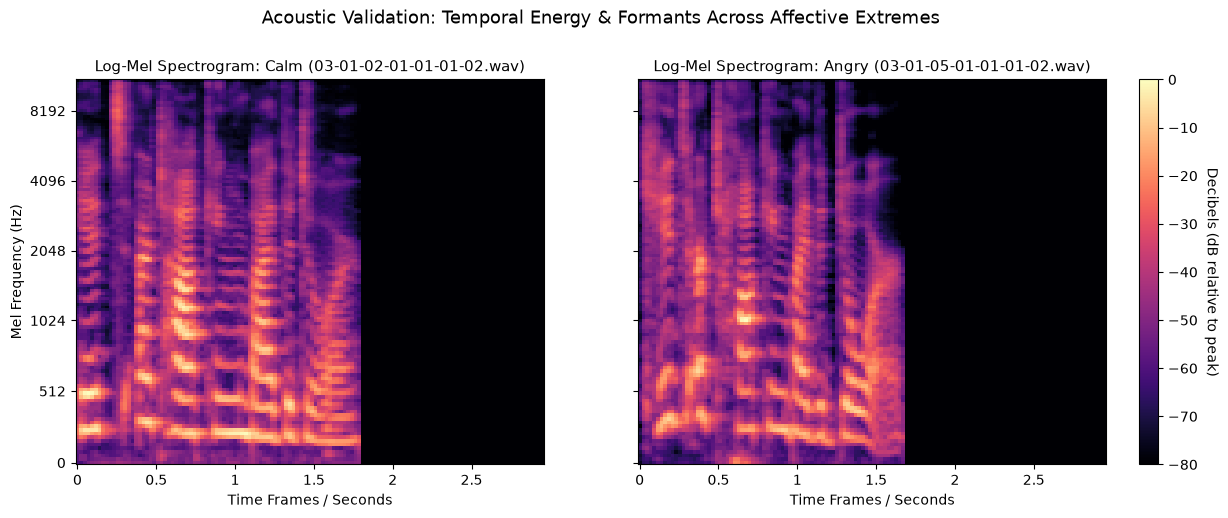

In [21]:
# Identify representative index pairs for contrasting emotions (e.g., Actor 01 Female)
idx_calm = df_cleaned[
    (df_cleaned["emotion"] == "calm") & 
    (df_cleaned["gender"] == "F") & 
    (df_cleaned["intensity"] == "normal")
].index[0]

idx_angry = df_cleaned[
    (df_cleaned["emotion"] == "angry") & 
    (df_cleaned["gender"] == "F") & 
    (df_cleaned["intensity"] == "normal")
].index[0]

# Compute spectrograms
spec_calm = extract_log_mel_spectrogram(df_cleaned.loc[idx_calm, "file_path"])
spec_angry = extract_log_mel_spectrogram(df_cleaned.loc[idx_angry, "file_path"])

# Plot side-by-side Log-Mel spectrograms
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# 1. Calm representation
img_calm = librosa.display.specshow(
    spec_calm,
    sr=SR,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    fmax=SR // 2,
    ax=axes[0],
    cmap="magma",
    vmin=-80.0,
    vmax=0.0,
)
axes[0].set_title(f"Log-Mel Spectrogram: Calm ({df_cleaned.loc[idx_calm, 'file_name']})", fontsize=11)
axes[0].set_xlabel("Time Frames / Seconds")
axes[0].set_ylabel("Mel Frequency (Hz)")

# 2. Angry representation
img_angry = librosa.display.specshow(
    spec_angry,
    sr=SR,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    fmax=SR // 2,
    ax=axes[1],
    cmap="magma",
    vmin=-80.0,
    vmax=0.0,
)
axes[1].set_title(f"Log-Mel Spectrogram: Angry ({df_cleaned.loc[idx_angry, 'file_name']})", fontsize=11)
axes[1].set_xlabel("Time Frames / Seconds")
axes[1].set_ylabel("")

# Add shared colorbar
cbar = fig.colorbar(img_angry, ax=axes, orientation="vertical", fraction=0.02, pad=0.03)
cbar.set_label("Decibels (dB relative to peak)", rotation=270, labelpad=15)

plt.suptitle("Acoustic Validation: Temporal Energy & Formants Across Affective Extremes", fontsize=13, y=1.02)
plt.show()

Comparing the Log-Mel spectrograms for **Calm** versus **Angry** (same actor, normal intensity) confirms three key acoustic behaviors:

* **High-Frequency Energy:** The calm sample concentrates power below 2,048 Hz, while the angry sample pushes intense energy past 4,096 Hz, reflecting increased vocal effort and physiological arousal.
* **Harmonic Detail:** Formant bands ($F_1, F_2, F_3$) and pitch contours show up as distinct horizontal ridges rather than blurred noise, verifying that our STFT settings preserve fine spectral structure.
* **Trim & Padding Integrity:** Both recordings start immediately at 0.0s (validating our `top_db=25` silence trimming) and end around 1.6s–1.8s, with the remaining frames padded to -80.0 dB to form an identical 128x128 grid.

With this confirmation, we can now run the process on all 1440 clips in prepartion for our network.

In [30]:
# Ensure target directory exists
tensors_dir = project_root / "data" / "processed" / "spectrograms"
tensors_dir.mkdir(parents=True, exist_ok=True)

# Defensive conversion to pure Python strings
audio_paths: list[str] = [str(p) for p in df_cleaned["file_path"]]
num_samples = len(audio_paths)

# Pre-allocate 3D array: (1440, 128, 128) - the 3d frame of all clips
X_spectrograms = np.empty((num_samples, N_MELS, TARGET_FRAMES), dtype=np.float32)

# Batch extraction loop
for i, path_str in enumerate(tqdm(audio_paths, desc="Extracting Log-Mel Spectrograms")):
    X_spectrograms[i] = extract_log_mel_spectrogram(path_str)

# Verify shape and in-memory size
print(f"\nExtraction complete.")
print(f"Tensor Array Shape: {X_spectrograms.shape} (Expected: (1440, 128, 128))")
print(f"In-Memory Size:     {X_spectrograms.nbytes / (1024**2):.2f} MB")

# Save compressed archive with labels and grouping IDs
tensor_save_path = tensors_dir / "04_spectrogram_tensors.npz"

# Verify alignment with df_features if loaded
assert len(X_spectrograms) == len(df_cleaned), "Row mismatch between X and metadata!"

# Serialized tensor bundle with explicit numpy types
np.savez_compressed(
    tensor_save_path,
    X=X_spectrograms,
    y=df_cleaned["target"].to_numpy(dtype=str),
    actor_ids=df_cleaned["actor_id"].to_numpy(dtype=np.int64),
    genders=df_cleaned["gender"].to_numpy(dtype=str),
    emotions=df_cleaned["emotion"].to_numpy(dtype=str),
    intensities=df_cleaned["intensity"].to_numpy(dtype=str),
    statements=df_cleaned["statement"].to_numpy(dtype=str),
    file_names=df_cleaned["file_name"].to_numpy(dtype=str),
)

print(f"Serialized tensor bundle to: {tensor_save_path}")
print(f"Compressed File Size:        {tensor_save_path.stat().st_size / (1024**2):.2f} MB")
print(f"Sample targets:              {df_cleaned['target'].iloc[:5].tolist()}")

Extracting Log-Mel Spectrograms: 100%|██████████| 1440/1440 [00:03<00:00, 367.95it/s]



Extraction complete.
Tensor Array Shape: (1440, 128, 128) (Expected: (1440, 128, 128))
In-Memory Size:     90.00 MB
Serialized tensor bundle to: /Users/abhisheknigam/workspace/github/my-ai/speech-emotion-router/data/processed/spectrograms/04_spectrogram_tensors.npz
Compressed File Size:        46.91 MB
Sample targets:              ['M_neutral', 'M_neutral', 'M_neutral', 'M_neutral', 'M_calm']


In [ ]:
# # Loading and Validation Code
# tensors_dir = project_root / "data" / "processed" / "spectrograms"
# tensor_save_path = tensors_dir / "04_spectrogram_tensors.npz"
# loaded = np.load(tensor_save_path)
# print("Keys present:", list(loaded.keys()))
# print("X shape:", loaded["X"].shape)
# print("y shape:", loaded["y"].shape)
# print("Unique target classes:", len(np.unique(loaded["y"])))
# print("Unique actors:", len(np.unique(loaded["actor_ids"])))

Expected output
```python
Keys present: ['X', 'y', 'actor_ids', 'genders', 'emotions', 'intensities', 'statements', 'file_names']
X shape: (1440, 128, 128)
y shape: (1440,)
Unique target classes: 16
Unique actors: 24
```

## Conclusion

Phase 04 successfully transitions our feature pipeline from static 1D summary vectors to 2D continuous time-frequency representations. This phase had a lot of audio engineering theory, even more than phase 02, EDA. The key takeaways are:

- All 1,440 audio recordings underwent leading/trailing silence trimming (`top_db=25`), STFT projection across 128 Mel filter banks, and dynamic range compression to decibels relative to peak amplitude.
- Time dimensions are standardized to 128 frames via decibel floor padding and center cropping, producing consistent `(128, 128)` float32 arrays.
- Serialized the complete bundle to `data/processed/spectrograms/04_spectrogram_tensors.npz` without Python object pickling dependencies.
- Verified exact array dimensions (`1440, 128, 128`), complete 16-class compound target distribution, and all 24 speaker groupings (`actor_ids`) for downstream cross-validation.

We are now prepared to begin the CNN modeling.